# MOdel selection and evaluation metrics decision framework

# 1.How to select right machine learnig model

Choosing a machine learning model depends on :

--The nature of target variable y

--the size and dimensionaluity of datatset x

--the required balance between interpretability and predictive power

                    Is your target variable (y) known?
                                      |
                     +----------------+----------------+
                     | Yes                             | No
           Supervised Learning               Unsupervised Learning
                     |                        (K-Means, PCA, DBSCAN)
         +-----------+-----------+
         | **Continuous**            | Categorical / Discrete
     **Regression**                Classification
  **(Linear Regression,**         |     (Logistic Regression, SVM,
   **Decision Tree Regressor,**  |      Decision Trees, Random Forest,
   **Random Forest Regressor)**   |      Gradient Boosting, Naive Bayes)

# Step 1: Identify the task type from the target variable (y)

# supervised classification: 

If y consists of discrete categories or lables(e.g o for malignnat and 1 foe bening, spam or not spam), use classification algorithms such as support vector machines, logistic regression, decision trees,  random forest or k-nearest neighbor.

# supervised regression:

If y is a continous numerical quantity(e,g housing prices, tenperature, fuel efficiency) use regression algorithms sucha as linear regression, ridge/lasso, decision tree regressors.

# Unsupervised learning:

if there is no target variable y , use clustering (e.g k-means, DBSCAN, or dimensionality reduction (e.g PCA))

# Step 2 : Access data characteistics and decision boundaries

# Linear vs non-linear Boundaries:

 If features are linearly separable, simple models like Logistic Regression or Linear SVM work effectively. If the boundary between classes is complex or curved, non-parametric or kernelized models like SVM with RBF Kernel or Random Forests are required.
 
# Feature-to-Sample Ratio (p vs. N): 

When the number of features (p) is large relative to samples (N), SVM performs well. When $N$ is very large, tree ensembles (XGBoost, LightGBM) scale better.

# Breakdown and understanding of  **step 2 ** in small parts:

# WHat is decision boundary:

Imagine a scatter plot with two colors of dots: Red (Malignant tumor) and Blue (Benign tumor).

A decision boundary is simply the border line or fence that a machine learning model draws on the graph to separate the Red dots from the Blue dots.

Feature 2 (e.g., Texture)
       ^
       |   (Red)  (Red)     |   (Blue)  (Blue)
       |      (Red)         |      (Blue)
       |                    |
       |  <-- Linearly Separable Boundary -->
       +----------------------------------------> Feature 1 (e.g., Radius)

# 1.Linearly separable boundaries: 

You can draw a single, perfectly straight line (in 2d space) ora flat sheet/plane (3d) that cleeanly separets class 0 from class 1.

Analogy (The Ruler): Put apples on the left side of a table and oranges on the right side. You can lay down a straight wooden ruler between them to separate them completely.

When to use simple models:

If your data looks like this, simple models like Logistic Regression or Linear Support Vector Machine (SVM) work best.

Why? They are fast, simple, and won't overcomplicate a simple problem.

# 2.Non linear boundaries:

The boundary between classes is curved, circular, S-shaped, or irregular. A single straight line will fail miserably—it will cut right through the groups and make huge prediction errors.

Non-Linear Scenario (e.g., Concentric Circles / Ring)

       ^
       |     (Blue)   (Blue)   (Blue)
       |   (Blue)   (Red)  (Red)   (Blue)
       |   (Blue)   (Red)  (Red)   (Blue)
       |     (Blue)   (Blue)   (Blue)
       +----------------------------------->

Analogy (The Bullseye Target): Imagine a bullseye target where the center circle is Red and the outer ring surrounding it is Blue.

If you try to draw a straight line across the target, it must pass through the outer Blue ring, then the Red center, and back into the Blue ring. A straight line cannot separate Red from Blue!

To separate them, you need a curved line (a circle) around the center.

**When to use non-linear models:**

When your features have complex interactions.

**Models used:**

SVM with RBF (Radial Basis Function) Kernel: It mathematically transforms 2D curved data into a higher-dimensional space where a flat slice can separate it, creating smooth curved boundaries.

Random Forest / XGBoost: They draw a grid of multiple "step-by-step" boxy boundaries (if radius > 15 AND texture < 20) to carve around complex shapes.

# Feature to sample ration (p vs N)

To understand this, first clarify what p and N mean:
p} = {Number of Features (Columns in your dataset, e.g., age, income, blood pressure)}

{N} = \text{Number of Samples (Rows in your dataset, e.g., total patients or transactions)}

**Scenario A:** 
High $p$, Small $N$ (p \ge N$ or $p \approx N$)

Meaning: You have many columns (features), but few rows (samples).

Real-World Example (Genomics / DNA Research):You study a rare disease with only 100 patients ($N = 100$).For each patient, you test 20,000 gene expressions ($p = 20,000$).Here, $p \gg N$ (20,000 columns vs. 100 rows).

--Q : Why does svm perform well here?

**High-Dimensional Geometry:** When $p$ is very large, data points live in a 20,000-dimensional space. In high dimensions, data points naturally spread far apart from each other, making it very easy to find a flat boundary (hyperplane) that passes between them.

**Maximum-Margin Principle:** SVM does not look at all 100 patients equally; it only focuses on the key boundary points called Support Vectors to construct the widest possible "safety zone" (margin) between classes. This prevents it from overfitting.

--Q : why do decision trees struggle here?

With 20,000 features and only 100 samples, a decision tree will easily pick random "noisy" features by chance to split the data, leading to severe overfitting.

**Scenrario B:**
Very Large $N$ ($N$ is huge, e.g., $N = 1,000,000+$ rows)

Meaning: You have a massive number of rows (samples), but a moderate number of columns.Real-World Example (E-Commerce / Banking):Credit card fraud detection with 10,000,000 transaction records ($N = 10,000,000$).

Each transaction has 30 attributes ($p = 30$) like amount, time, location, etc.

--Q 1: Why do tree ensemble (XGboost, lightGBM) scale better here?

**Computation Speed:** Tree ensembles split data using fast conditional thresholds (if amount > $500). Modern algorithms like LightGBM group continuous features into discrete bins (histograms), allowing them to process millions of rows in seconds.

**Complex Pattern Matching:** With millions of rows, tree ensembles can learn intricate patterns across combinations of features without running out of memory.

--Q : Why does SVM struggle here?
Standard SVM training involves solving a quadratic optimization problem that calculates pairwise relationships between samples.

The computational complexity of standard SVM scales between $\mathcal{O}(N^2)$ and $\mathcal{O}(N^3)$.

If $N = 1,000,000$, $N^2 = 1,000,000,000,000$ operations! Standard SVM will take hours or crash your computer due to memory exhaustion.

# 2. which metrics to import and their definition:

In classification tasks (such as the breast cancer diagnosis dataset in this notebook), evaluating performance using only Accuracy can be misleading, especially when classes are imbalanced or when false negatives carry severe consequences (e.g., diagnosing a malignant tumor as benign).

# Classification evaluation metrics:

# 1.Confusion metrics:

A tabular layout summarizing model predictions against ground-truth labels:

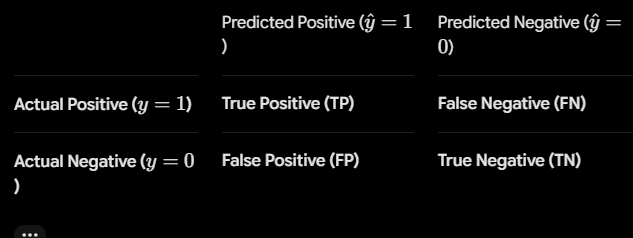

True Positive (TP): Malignant tumor correctly identified as malignant.

True Negative (TN): Benign tumor correctly identified as benign.

False Positive (FP / Type I Error): Benign tumor incorrectly classified as malignant.

False Negative (FN / Type II Error): Malignant tumor incorrectly classified as benign (most dangerous in medical diagnosis).

# 2.Accuracy:

$$\text{Accuracy} = \frac{\text{TP} + \text{TN}}{\text{TP} + \text{TN} + \text{FP} + \text{FN}}$$

def: The proprtion of total correct predictions out of ALL SAMLPES.

--when to use: When classes are balanced (50/50 split) and all errors carry equAL cost.

# 3.Precision(Positive predicted values):

$$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$

def:The proportion of predicted positive cases that were actually positive.

--when to use: When the cost of false positive is high (e.g spam detection, where labelling a critical email as spam is costly.)

# 4.Recall(sensiitvity/True positive rate):

$$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$

def: The proportion of actual positive cases that the model successfully identified.

--when to use: When the cost of false negative is catastrophic(e.g. medical diagnosis, where missing a malignnat tumor can be fatal)

# 5.F1-score:

$$\text{F1-Score} = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

def: The harmonic mean pf precision and accuaracy.

--when to use: Provides a single balanced metric when dealing with imbalances datasets.

# 6.ROC-AUC(area under curve operating characteritic curve)

$$\text{TPR} = \frac{\text{TP}}{\text{TP} + \text{FN}}, \quad \text{FPR} = \frac{\text{FP}}{\text{FP} + \text{TN}}$$

def: Measures the models ability to discriminate between classes across all possible classification threshold. An AUC of 1.0 represents a perfect model, 0.5 represents random guessing.

# Import libraries

In [12]:
from sklearn.datasets import load_breast_cancer
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.svm import SVC

**Interpretation:**

**from sklearn.inspection import DecisionBoundaryDisplay:** 
--
--Why use: A utility class designed to evaluate a fitted classifier over a 2d feature grid and display its decision regions automatically without requiring manual creation of coordinate matrices via np.meshgrid

**from sklearn.svm import SVC:**
--
--why:implement support vector machine classification using C-support vector classification based on libsvm.

# Load Dataset

In [13]:
cancer = load_breast_cancer()

In [14]:
cancer

{'data': array([[1.799e+01, 1.038e+01, 1.228e+02, ..., 2.654e-01, 4.601e-01,
         1.189e-01],
        [2.057e+01, 1.777e+01, 1.329e+02, ..., 1.860e-01, 2.750e-01,
         8.902e-02],
        [1.969e+01, 2.125e+01, 1.300e+02, ..., 2.430e-01, 3.613e-01,
         8.758e-02],
        ...,
        [1.660e+01, 2.808e+01, 1.083e+02, ..., 1.418e-01, 2.218e-01,
         7.820e-02],
        [2.060e+01, 2.933e+01, 1.401e+02, ..., 2.650e-01, 4.087e-01,
         1.240e-01],
        [7.760e+00, 2.454e+01, 4.792e+01, ..., 0.000e+00, 2.871e-01,
         7.039e-02]]),
 'target': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
        1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
        1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
        1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0

# Internal breakdown:

data = A 2D numpy array of shape (569,30) containing continous nunerical measurements exracted from digitized images of fine needlw aspiartes(FNA) of breast masses.

target = A 1D array of shape(569,) containing binary targets(0 and 1).

target names = ----

# define x(features) and y(target)

In [18]:
x = cancer.data[:,:2] # extract mean radius and mean texture
y=cancer.target #0=malignnat and 1=benign

# Generate scatter plot

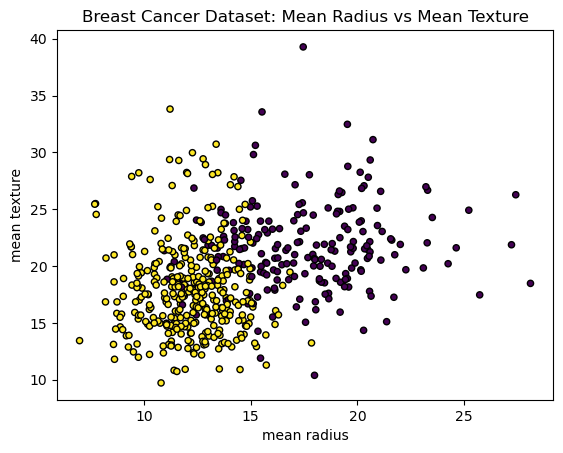

In [20]:
plt.scatter(x[:, 0], x[:, 1], c=y, s=20, edgecolors="k")
plt.xlabel(cancer.feature_names[0])  # 'mean radius'
plt.ylabel(cancer.feature_names[1])  # 'mean texture'
plt.title("Breast Cancer Dataset: Mean Radius vs Mean Texture")
plt.show()

# Interpretation

plt.scatter: overlays individual sample data points into the decision surface plot

x[:,0]: values for mean radius plotted along the x-axis

x[:,1]: vales for mean texture plotted along the x-axis

c=y: set color dased on target values

s=20: set marker point

# Critical thinking and logi building in machine learning

to make independent desicsion during ML projects,follow this decision-making framework

# ------------------Feature selection logic: Why 2 Features vs all 30 features?---------------------

the code extracts only 2 features:

x=cancer.data[:,:2]

**--why we done here:** Because human can only visualize 2D and 3D spaces easily. Selecting two features allow diresct plotting of decision boundaries using DecisionBoundaryDisplay.

**--Trade off anf production logic:**

Information Loss: Discarding 28 out of 30 features removes valuable diagnostic signal (e.g., 'worst concave points', 'mean area'), lowering potential model accuracy.

Curse of Dimensionality: In production models, use all relevant features ($30$ features). Use Dimensionality Reduction techniques like PCA (Principal Component Analysis) if features are collinear, or Feature Selection techniques (e.g., Feature Importance from Random Forests, Lasso Regularization) to reduce dimensions without arbitrary truncation.

# ------2. The Missing Step: 

Feature ScalingSupport Vector Machines compute Euclidean distances between data points in feature space:

$$d(x_i, x_j) = \sqrt{(x_{i1} - x_{j1})^2 + (x_{i2} - x_{j2})^2}$$

# Critical Analysis of the Notebook Code:

In cancer.data, 'mean radius' ranges from $6.98$ to $28.11$, while 'mean area' ranges from $143.5$ to $2501.0$.

Because the notebook ran SVC.fit(X, y) directly on raw features without scaling, features with larger numeric ranges dominate distance calculations, distorting the RBF kernel.

----------Best Practice Fix:

Always apply StandardScaler prior to distance-based algorithms (SVM, KNN, K-Means, PCA):

In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)
svm.fit(x_scaled,y)

SVC(gamma=0.5)

# Generalization and prevent overfitting

this notebook fits the svm model on the entire dataset without splitting it into training and test sets.

--**Why this is problematic:** Evaluating a model in the same data it trained in measures memorization rather generalization. High training performance does not guarantee accuracy on unseen data.

# Correct workflow

In [32]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

#split into x and y
x_train, x_test, y_train, y_test = train_test_split( x, y, test_size=0.2, random_state=42, stratify=y)

#scale features using training stats only
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

#train model
svm = SVC(kernel='rbf',gamma=0.5, C=1.0,probability=True)
svm.fit(x_train_scaled,y_train)

#evaluate on unseen data
y_pred = svm.predict(x_test_scaled)
y_proba = svm.predict_proba(x_test_scaled)[:,1]

print(classification_report(y_test,y_pred,target_names=cancer.target_names))
print('ROC-AUC SCORE:',roc_auc_score(y_test,y_proba))

              precision    recall  f1-score   support

   malignant       0.86      0.88      0.87        42
      benign       0.93      0.92      0.92        72

    accuracy                           0.90       114
   macro avg       0.90      0.90      0.90       114
weighted avg       0.90      0.90      0.90       114

ROC-AUC SCORE: 0.9470899470899472


# 4.Hyperparameter tunning

hyperparameters are manually choosen (gamma=0.5,c=0.1). Instead of guessing , use GridSearchCV or RandomizedSearchCv to systematically searcg for optimal hyperparameter combinations

In [29]:
from sklearn.model_selection import GridSearchCV

param_grid={
    'C':[0.1,1,10,100],
    'gamma':[0.001,0.01,0.1,1.0],
    'kernel':['rbf','linear']
}
grid = GridSearchCV(SVC(),param_grid,cv=5,scoring='recall')
grid.fit(x_train_scaled, y_train)

print("Best Parameters Found:", grid.best_params_)

Best Parameters Found: {'C': 0.1, 'gamma': 0.001, 'kernel': 'rbf'}
